# Try tuning leiden (resolution) and LSI (n_components)

### only on H3K27ac for now

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
import anndata as ad
from loading import *
import muon
import scanpy as sc

#load data with AnnData
H3K27ac_ad, H3K27me3_ad = load_data_in_AnnData()

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [2]:
from dim_reduction import *
from labels import *
#by defaut, we took 20 factor increasd
H3K27ac = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, factor=20)
group_cell_types(H3K27ac)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 50 cells having non-zero values: 105051


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


24 classes -> 18 classes (smallest: EXC, 40 cells)


AnnData object with n_obs × n_vars = 4805 × 105051
    obs: 'cell_id', 'cell_type', 'sample', 'nCounts_bins_H3K27ac', 'nCounts_bins_H3K27me3', 'cell_type_grouped'
    var: 'chrom', 'start', 'end'
    uns: 'lsi'
    obsm: 'X_lsi'
    varm: 'LSI'
    layers: 'tfidf'

18


Exception in thread Thread-4 (_readerthread):
Traceback (most recent call last):
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\ipykernel\ipkernel.py", line 772, in run_closure
    _threading_Thread_run(self)
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\subprocess.py", line 1515, in _readerthread
    buffer.append(fh.read())
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\codecs.py", line 322, in decode
    (result, consumed) = self._buffer_decode(data, self.errors, final)
UnicodeDecodeError: 'utf-8' codec can't decode byte 0x82 in position 110: invalid start byte
c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\Learning-Compact-Embeddings-of-Single-Cell-Histone-PTMs\clustering.py:15: FutureWarning: In 

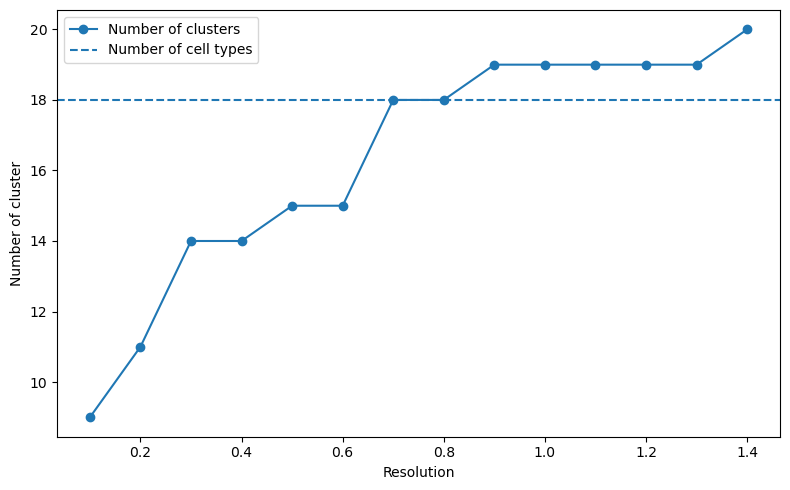

In [ ]:
from clustering import *
import matplotlib.pyplot as plt

#testing different value for resolution
resolution = np.arange(0.1, 1.5, 0.1)
nbre_clust = []
nbre_cell_type = len(np.unique(H3K27ac.obs['cell_type_grouped']))
print(nbre_cell_type)
for res in resolution :
    clustering(H3K27ac, Kmeans=False, resolution=res, cell_type='cell_type_grouped')
    clust = len(np.unique(H3K27ac.obs['leiden']))
    nbre_clust.append(clust)
    
plt.figure(figsize=(8, 5))
plt.plot(resolution, nbre_clust, marker='o', label="Number of clusters")
plt.axhline(nbre_cell_type, linestyle='--', label="Number of cell types")
plt.legend()
plt.xlabel("Resolution")
plt.ylabel("Number of cluster")
plt.tight_layout()
plt.show()

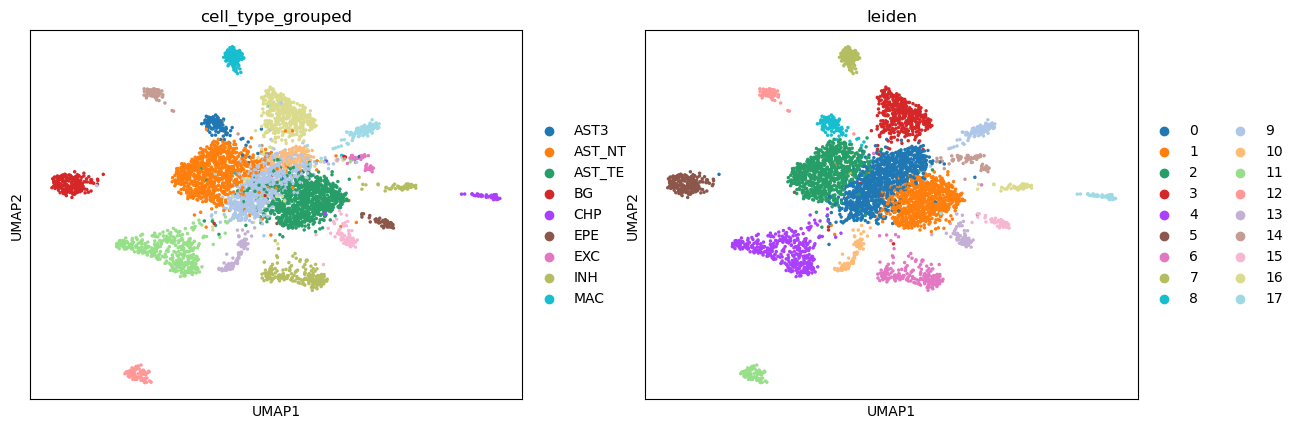

In [4]:
clustering(H3K27ac, Kmeans=False, visualization=True, resolution=0.7, cell_type='cell_type_grouped')

In [15]:
#test component 
H3K27ac_comp = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, factor=20, n_components=200)
group_cell_types(H3K27ac_comp)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 50 cells having non-zero values: 105051


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


24 classes -> 18 classes (smallest: EXC, 40 cells)


AnnData object with n_obs × n_vars = 4805 × 105051
    obs: 'cell_id', 'cell_type', 'sample', 'nCounts_bins_H3K27ac', 'nCounts_bins_H3K27me3', 'cell_type_grouped'
    var: 'chrom', 'start', 'end'
    uns: 'lsi'
    obsm: 'X_lsi'
    varm: 'LSI'
    layers: 'tfidf'

(4805, 199)
Components: 10, shape: (4805, 10)
Clustering score for leiden :
 - NMI score : 0.902, ARI score : 0.889
 - ASW score : 0.717, LISI score (mean) : 1.049
Components: 20, shape: (4805, 20)
Clustering score for leiden :
 - NMI score : 0.916, ARI score : 0.893
 - ASW score : 0.597, LISI score (mean) : 1.087
Components: 30, shape: (4805, 30)
Clustering score for leiden :
 - NMI score : 0.897, ARI score : 0.862
 - ASW score : 0.544, LISI score (mean) : 1.242
Components: 40, shape: (4805, 40)
Clustering score for leiden :
 - NMI score : 0.862, ARI score : 0.805
 - ASW score : 0.520, LISI score (mean) : 1.404
Components: 50, shape: (4805, 50)
Clustering score for leiden :
 - NMI score : 0.814, ARI score : 0.592
 - ASW score : 0.521, LISI score (mean) : 1.336
Components: 60, shape: (4805, 60)
Clustering score for leiden :
 - NMI score : 0.795, ARI score : 0.561
 - ASW score : 0.511, LISI score (mean) : 1.415
Components: 70, shape: (4805, 70)
Clustering score for leiden :
 - NMI score

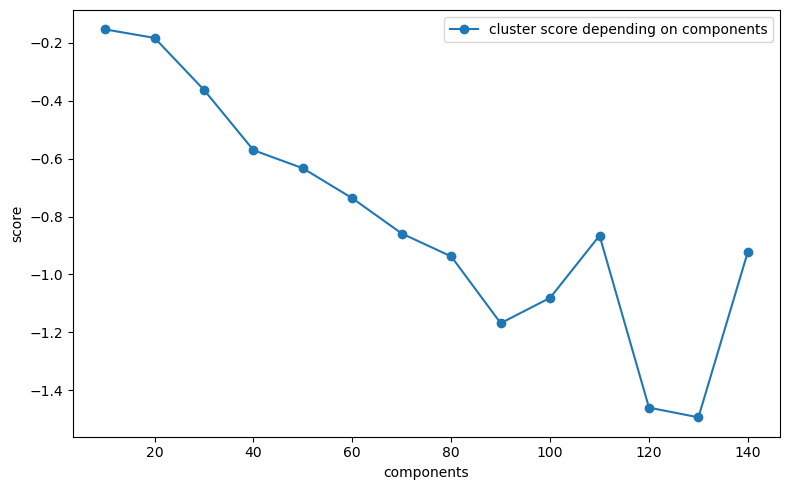

In [16]:
from test_clustering import *
test_comp = np.arange(10, 150, 10)
lsi = H3K27ac_comp.obsm['X_lsi']
print(lsi.shape)
scores = []
for comp in test_comp :
    adata_tmp = H3K27ac_comp.copy()
    adata_tmp.obsm['X_lsi'] = lsi[:, :comp]
    print(
        f"Components: {comp}, "
        f"shape: {adata_tmp.obsm['X_lsi'].shape}"
    )
    clustering(adata_tmp, Kmeans=False, resolution=0.7, cell_type='cell_type_grouped')
    sc = clust_score(adata_tmp, nmi_ari=True, asw_lisi=True, clust_name='leiden', type_obs='X_lsi', cell_type='cell_type_grouped')
    eval = np.mean(sc[:2]) - sc[3]
    scores.append(eval)
    
plt.figure(figsize=(8, 5))
plt.plot(test_comp, scores, marker='o', label="cluster score depending on components")
plt.legend()
plt.xlabel("components")
plt.ylabel("score")
plt.tight_layout()
plt.show()

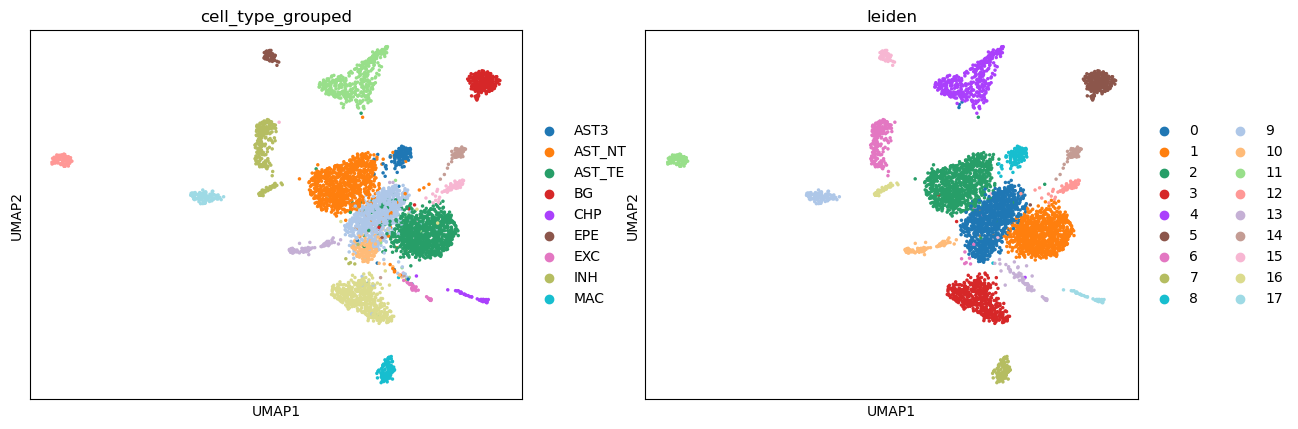

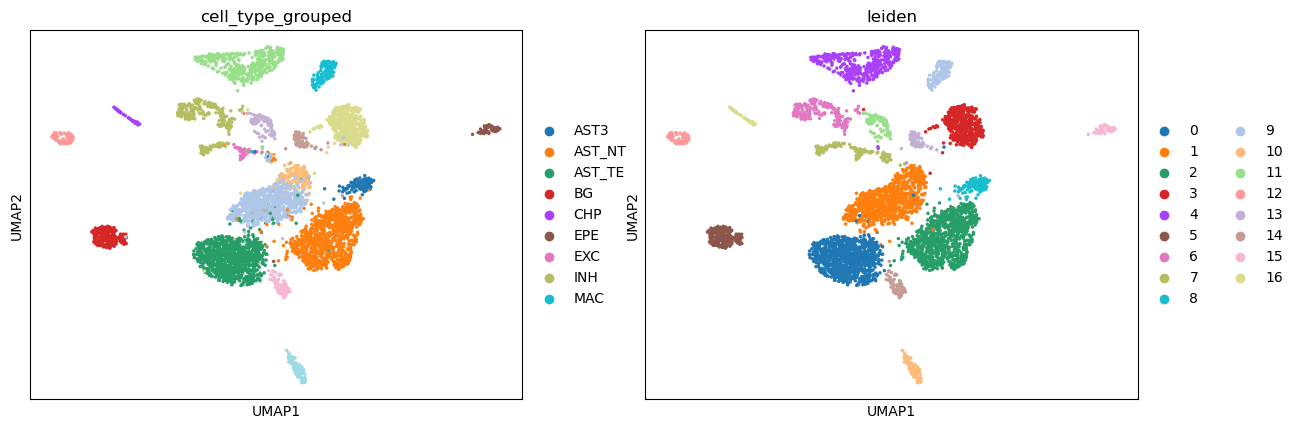

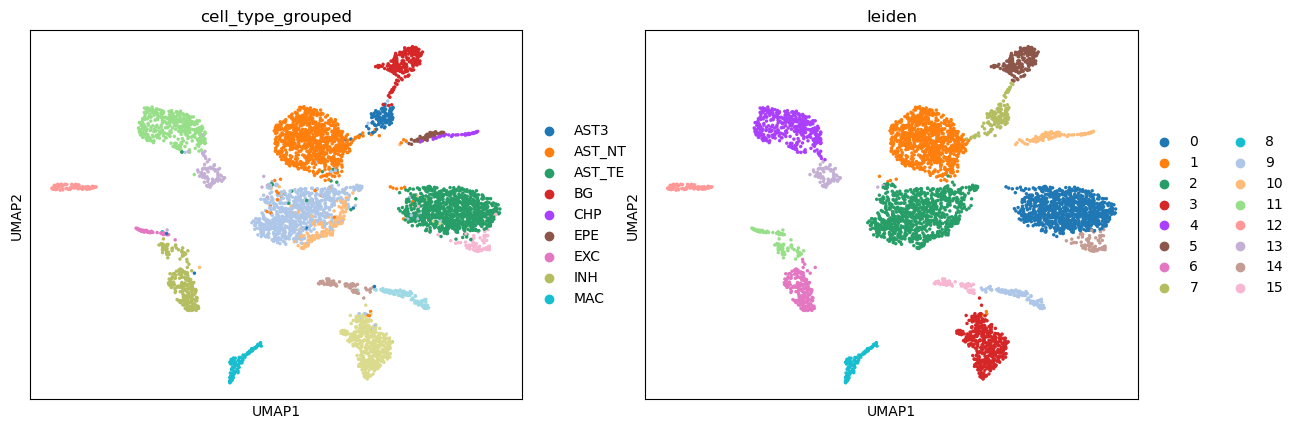

In [17]:
H3K27ac_comp.obsm['X_lsi'] = lsi[:, :30]
clustering(H3K27ac_comp, Kmeans=False, visualization=True, resolution=0.7, cell_type='cell_type_grouped')
H3K27ac_comp.obsm['X_lsi'] = lsi[:, :20]
clustering(H3K27ac_comp, Kmeans=False, visualization=True, resolution=0.7, cell_type='cell_type_grouped')
H3K27ac_comp.obsm['X_lsi'] = lsi[:, :10]
clustering(H3K27ac_comp, Kmeans=False, visualization=True, resolution=0.7, cell_type='cell_type_grouped')